In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 1000

df = pd.DataFrame({
    "Order_ID": range(1001, 1001 + n),

    "Date": np.random.choice(
        pd.date_range("2025-01-01", "2025-12-31"),
        n
    ),

    "Product": np.random.choice(
        ["Laptop", "Mobile", "Tablet",
         "Headphones", "Keyboard", "Mouse"],
        n
    ),

    "Category": np.random.choice(
        ["Electronics", "Accessories", "Computers"],
        n
    ),

    "Region": np.random.choice(
        ["North", "South", "East", "West"],
        n
    ),

    "Quantity": np.random.randint(1, 6, n),

    "Unit_Price": np.random.randint(100, 50001, n)
})

df["Sales"] = df["Quantity"] * df["Unit_Price"]

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

display(df.head())

print("Dataset shape:", df.shape)

,Order_ID,Date,Product,Category,Region,Quantity,Unit_Price,Sales
0,1849,2025-01-01,Mouse,Computers,East,5,35270,176350
1,1678,2025-01-01,Headphones,Accessories,North,4,12527,50108
2,1649,2025-01-01,Mobile,Computers,South,2,5798,11596
3,1756,2025-01-01,Tablet,Electronics,North,5,29731,148655
4,1992,2025-01-01,Mobile,Accessories,East,3,3041,9123


Dataset shape: (1000, 8)


In [4]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order_ID    1000 non-null   int64         
 1   Date        1000 non-null   datetime64[ns]
 2   Product     1000 non-null   object        
 3   Category    1000 non-null   object        
 4   Region      1000 non-null   object        
 5   Quantity    1000 non-null   int64         
 6   Unit_Price  1000 non-null   int64         
 7   Sales       1000 non-null   int64         
dtypes: datetime64[ns](1), int64(4), object(3)
memory usage: 62.6+ KB

Statistical Summary:


,Order_ID,Date,Quantity,Unit_Price,Sales
count,1000.000000,1000,1000.000000,1000.000000,1000.000000
mean,1500.500000,2025-07-01 13:22:04.800000,2.957000,25495.135000,75283.661000
min,1001.000000,2025-01-01 00:00:00,1.000000,291.000000,698.000000
25%,1250.750000,2025-04-08 00:00:00,2.000000,13087.750000,27806.750000
50%,1500.500000,2025-07-01 12:00:00,3.000000,25641.500000,55695.500000
75%,1750.250000,2025-09-27 06:00:00,4.000000,37526.750000,110250.000000
max,2000.000000,2025-12-31 00:00:00,5.000000,49977.000000,249885.000000
std,288.819436,NaN,1.434995,14379.021329,60610.884036



Missing Values:
Order_ID      0
Date          0
Product       0
Category      0
Region        0
Quantity      0
Unit_Price    0
Sales         0
dtype: int64

Duplicate Rows:
0


In [5]:
# Remove duplicate records
df = df.drop_duplicates()

# Handle missing values
df = df.dropna(
    subset=["Order_ID", "Date", "Product", "Category",
            "Region", "Quantity", "Unit_Price"]
)

# Ensure valid numerical values
df = df[
    (df["Quantity"] > 0) &
    (df["Unit_Price"] >= 0)
].copy()

# Recalculate sales
df["Sales"] = df["Quantity"] * df["Unit_Price"]

print("Data cleaning completed!")
print("Final dataset shape:", df.shape)

Data cleaning completed!
Final dataset shape: (1000, 8)


In [6]:
total_revenue = df["Sales"].sum()
total_orders = df["Order_ID"].nunique()
units_sold = df["Quantity"].sum()
average_order_value = total_revenue / total_orders

print("RETAIL SALES SUMMARY")
print("-" * 30)
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Units Sold: {units_sold:,}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")

RETAIL SALES SUMMARY
------------------------------
Total Revenue: ₹75,283,661.00
Total Orders: 1,000
Units Sold: 2,957
Average Order Value: ₹75,283.66


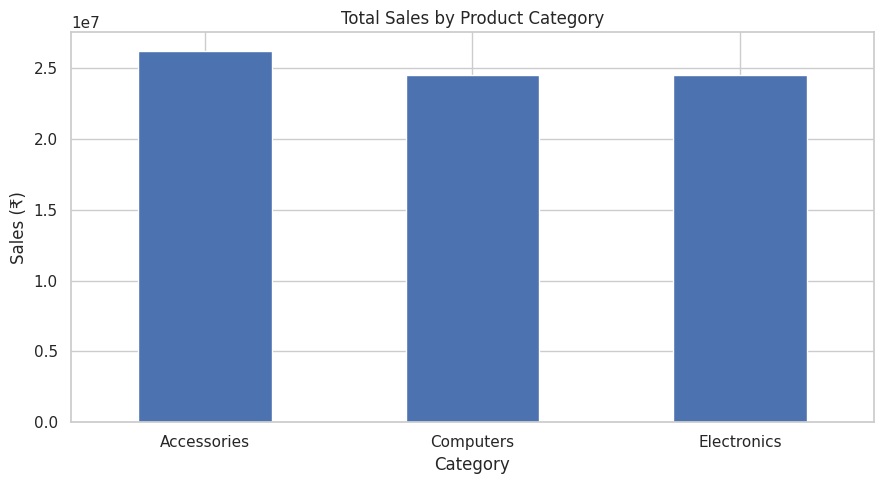

In [7]:
category_sales = (
    df.groupby("Category")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

category_sales.plot(kind="bar")

plt.title("Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

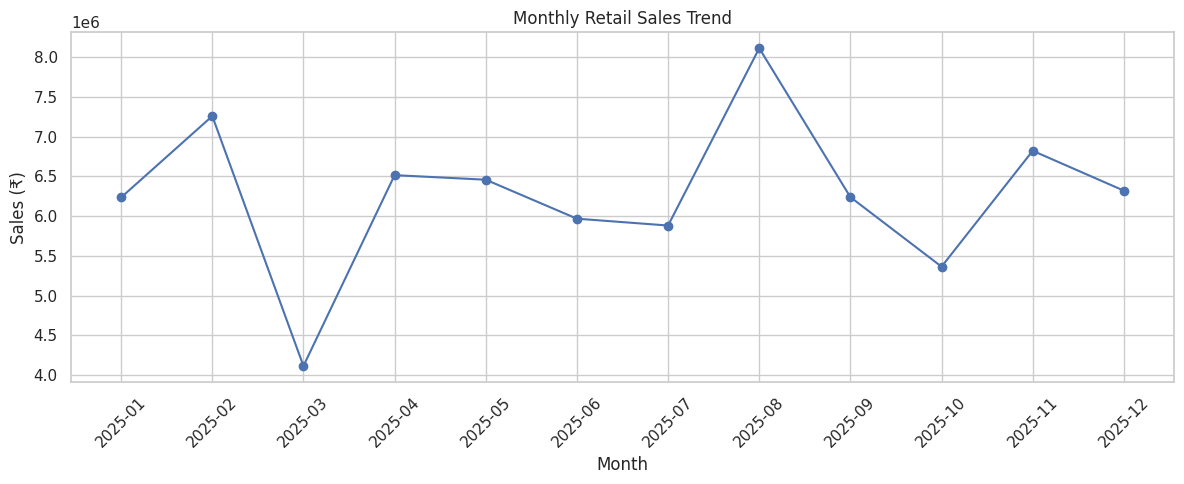

In [8]:
df["Month"] = df["Date"].dt.to_period("M").astype(str)

monthly_sales = (
    df.groupby("Month")["Sales"]
      .sum()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

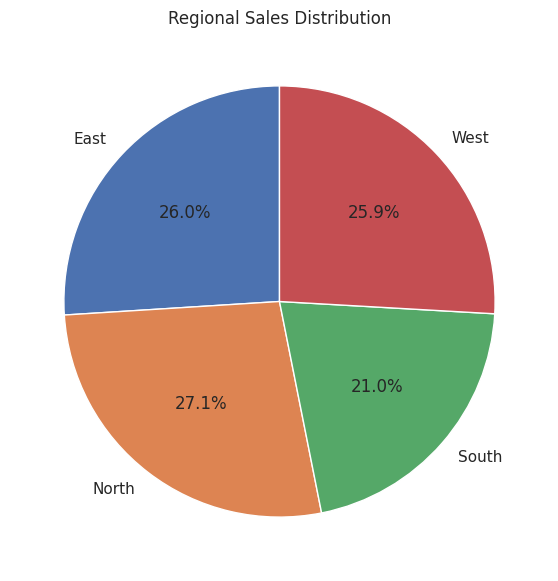

In [9]:
region_sales = df.groupby("Region")["Sales"].sum()

plt.figure(figsize=(7, 7))

plt.pie(
    region_sales,
    labels=region_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Regional Sales Distribution")
plt.show()

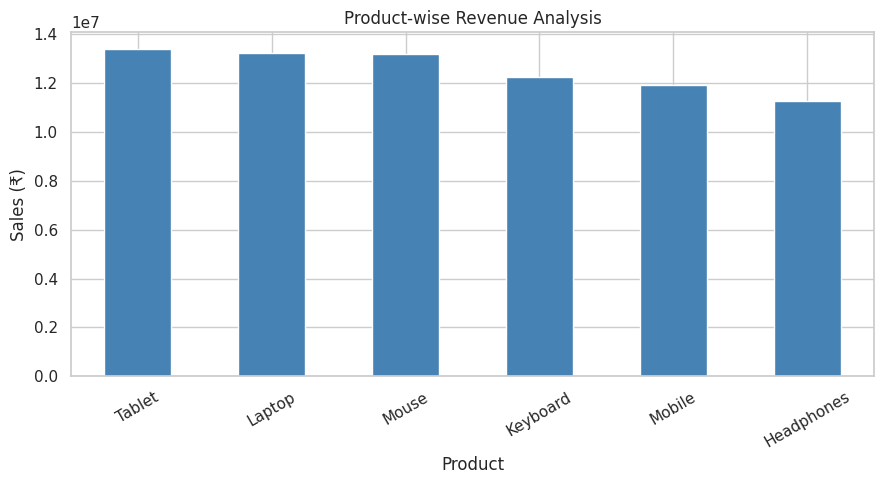

In [10]:
product_sales = (
    df.groupby("Product")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

product_sales.plot(kind="bar", color="steelblue")

plt.title("Product-wise Revenue Analysis")
plt.xlabel("Product")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [11]:
df.to_csv(
    "Retail_Sales_Data.csv",
    index=False
)

print("Dataset exported successfully!")

Dataset exported successfully!


In [12]:
from google.colab import files

files.download("Retail_Sales_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>